In [1]:
from itscalledsoccer.client import AmericanSoccerAnalysis
from plotnine import *
from colour import Color
import numpy as np
import pandas as pd

import numpy as np
from collections import defaultdict

import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

asa_client = AmericanSoccerAnalysis()
from sophso import *

In [2]:
games_df = decorate_team_ids(asa_client.get_games(leagues="nwsl", seasons="2025"))

gxg_df = asa_client.get_game_xgoals(game_ids=list(games_df.game_id))

games_df = games_df.merge(
    gxg_df[
        [
            "game_id",
            "home_team_xgoals",
            "away_team_xgoals",
            "home_xpoints",
            "away_xpoints",
        ]
    ],
    on="game_id",
)

games_df = games_df.sort_values("date_time_utc", ignore_index=True)

In [3]:
def explode_actions(action_list):
    row_dict = {}
    for action in action_list:
        action_type = action["action_type"]
        for action_value in [
            "goals_added_raw",
            # "goals_added_above_avg",
            "count_actions",
        ]:
            row_dict[f"{action_type} {action_value}"] = action[action_value]

    return row_dict

In [4]:
gplus_df = asa_client.get_player_goals_added(
    leagues="nwsl", season_name="2025", split_by_games=True
)

gplus_df = pd.concat(
    [gplus_df, pd.DataFrame(gplus_df.data.apply(explode_actions).to_list())], axis=1
)

gplus_df["Offensive goals added"] = gplus_df.loc[
    :,
    [
        "Dribbling goals_added_raw",
        # "Fouling goals_added_raw",
        # "Interrupting goals_added_raw",
        "Passing goals_added_raw",
        "Receiving goals_added_raw",
        "Shooting goals_added_raw",
    ],
].sum(axis=1)

gplus_df["Defensive goals added"] = gplus_df.loc[
    :,
    [
        # "Dribbling goals_added_raw",
        "Fouling goals_added_raw",
        "Interrupting goals_added_raw",
        # "Passing goals_added_raw",
        # "Receiving goals_added_raw",
        # "Shooting goals_added_raw",
    ],
].sum(axis=1)

gplus_df = decorate_team_ids(
    decorate_game_ids(
        gplus_df.groupby(["game_id", "team_id"])[
            ["Offensive goals added", "Defensive goals added"]
        ]
        .sum()
        .reset_index()
    )
).sort_values("date_time_utc")

gplus_df

KeyboardInterrupt: 

In [ ]:
gplus_df.query("game_id == 'EGMPadnj5a'")[
    ["team", "Offensive goals added", "Defensive goals added", "game_desc"]
]

,team,Offensive goals added,Defensive goals added,game_desc
94,BAY,0.7686,0.6463,BAY vs NJY: 2025-09-22
95,NJY,0.6894,0.4987,BAY vs NJY: 2025-09-22


,game_id,team_id,Offensive goals added,Defensive goals added,game_desc,date_time_utc,team,team_logo
183,aDQ0b6JW5E,aDQ0lzvQEv,0.4810,0.3158,ORL vs WAS: 2025-03-08,2025-03-08 01:00:00 UTC,WAS,https://american-soccer-analysis-headshots.s3....
182,aDQ0b6JW5E,XVqKeVKM01,1.2046,0.3207,ORL vs WAS: 2025-03-08,2025-03-08 01:00:00 UTC,ORL,https://american-soccer-analysis-headshots.s3....
117,KXMeZn0X56,XVqKeVKM01,2.5865,0.3611,ORL vs CHI: 2025-03-15,2025-03-15 00:00:00 UTC,ORL,https://american-soccer-analysis-headshots.s3....
71,9YqdjO2jMv,aDQ0lzvQEv,0.2661,0.5806,HOU vs WAS: 2025-03-15,2025-03-15 00:00:00 UTC,WAS,https://american-soccer-analysis-headshots.s3....
70,9YqdjO2jMv,4JMAk47qKg,0.8696,0.2761,HOU vs WAS: 2025-03-15,2025-03-15 00:00:00 UTC,HOU,https://american-soccer-analysis-headshots.s3....
...,...,...,...,...,...,...,...,...
78,9z5kjk7lMA,4wM4rZdqjB,1.2200,0.7280,KC vs SEA: 2025-09-20,2025-09-20 23:30:00 UTC,KC,https://american-soccer-analysis-headshots.s3....
35,315VpEX6Q9,Pk5LeeNqOW,0.9600,0.7852,POR vs SD: 2025-09-21,2025-09-21 02:00:00 UTC,POR,https://american-soccer-analysis-headshots.s3....
34,315VpEX6Q9,7VqG1lYMvW,1.0863,0.2657,POR vs SD: 2025-09-21,2025-09-21 02:00:00 UTC,SD,https://american-soccer-analysis-headshots.s3....
94,EGMPadnj5a,315VnJ759x,0.7686,0.6463,BAY vs NJY: 2025-09-22,2025-09-22 00:30:00 UTC,BAY,https://american-soccer-analysis-headshots.s3....


In [ ]:
def get_games_single_season(leagues="nwsl", seasons="2024"):
    games_df = decorate_team_ids(asa_client.get_games(leagues=leagues, seasons=seasons))
    gxg_df = asa_client.get_game_xgoals(game_ids=list(games_df.game_id))

    games_df = games_df.merge(
        gxg_df[
            [
                "game_id",
                "home_team_xgoals",
                "away_team_xgoals",
                "home_xpoints",
                "away_xpoints",
            ]
        ],
        on="game_id",
    )

    games_df = games_df.sort_values("date_time_utc", ignore_index=True)

    return games_df

In [ ]:
def get_games(leagues="nwsl", seasons="2024"):

    if isinstance(seasons, list):

        games_list = []
        for s in seasons:
            games_list.append(get_games_single_season(leagues=leagues, seasons=s))

        games_df = pd.concat(games_list, ignore_index=True)
    else:
        games_df = get_games_single_season(leagues=leagues, seasons=seasons)

    return games_df

In [ ]:
# get_games(leagues="nwsl", seasons="2025").query(
#     "home_team == 'LOU' | away_team == 'LOU'"
# ).T

Elo is a system for estimating player or team strength in zero sum games.

It's been adapted for use in soccer across the world. There are a variety of approaches that are all based on a similar formula

$R_n = R_o + P$
and
$P = K G (W - W_e)$

where

- $R_n$ The new team rating
- $R_o$ The old team rating
- $K$ Weight index regarding the tournament of the match
- $G$ A number from the index of goal differences
- $W$ The result of the match
- $W_e$ The expected result
- $P$ Points Change

Below I build a model that tests a few different changes and settings:

- First, inspired by [Trevor Larner](https://bsky.app/profile/trevorl.bsky.social) I want to determine if using xG to determine the outcome of matches rather than goals scored results in a better model.
- To do this, I will optimize both version of the model (score vs xg) so that we can compare the predictive abilities of each under relatively optimal conditions. To do this I will perform a grid search over the following parameters:
  - home rating: a parameter that adds to rating of home teams to reflect a "home field advantage"
  - k: the weight index, which determins how much ratings should change based on the result of a match
  - goal diff draw: this determins how much greater the xg value must be in order for a game to be considered a win.


In [ ]:
def elo_learn(
    games_df,
    k=10,
    rating_start=100,
    home_points=2,
    scaling_factor=100,
    learn_input="score",
    goal_diff_draw=0.25,
    starting_ratings=None,
    debug=False,
):

    if not starting_ratings:
        team_ratings = defaultdict(lambda: rating_start)
    else:
        team_ratings = starting_ratings.copy()

    for row, game in games_df.iterrows():

        if learn_input == "score":
            goal_diff = game.home_score - game.away_score
        elif learn_input == "xg":
            goal_diff = game.home_team_xgoals - game.away_team_xgoals
        else:
            raise ("learn_input must be either 'score' or 'xg'")

        rating_diff = (
            team_ratings[game.home_team] - team_ratings[game.away_team] + home_points
        )
        expected_result = 1 / (1 + 10 ** (-rating_diff / scaling_factor))

        if abs(goal_diff) <= 1:
            goal_index = 1
        elif abs(goal_diff) < 3:
            goal_index = (1 + abs(goal_diff)) / 2
        else:
            goal_index = (11 + abs(goal_diff)) / 8

        if abs(goal_diff) < goal_diff_draw:
            result = 0.5
        else:
            result = max(goal_diff / abs(goal_diff), 0)

        points_change = k * goal_index * (result - expected_result)

        if debug:
            print(game)
            print("expected result", expected_result)
            print("result", result)
            print("points change", points_change)
            print("home points before", team_ratings[game.home_team])
            print("home points after", team_ratings[game.home_team] + points_change)
            print("away points before", team_ratings[game.away_team])
            print("away points after", team_ratings[game.away_team] - points_change)

        team_ratings[game.home_team] = team_ratings[game.home_team] + points_change
        team_ratings[game.away_team] = team_ratings[game.away_team] - points_change

    ratings_df = pd.DataFrame(team_ratings.items(), columns=["team", "rating"])

    return ratings_df, team_ratings

In [ ]:
def get_predictions(ratings_df, games_df, home_points=2, scaling_factor=100, **kwargs):

    ratings_map = dict(zip(ratings_df.team, ratings_df.rating))

    ratings_diff = (
        games_df.home_team.map(ratings_map)
        - games_df.away_team.map(ratings_map)
        + home_points
    )

    home_prob = 1 / (1 + 10 ** (-ratings_diff / scaling_factor))
    games_df["home_prob"] = home_prob

    return games_df

In [ ]:
def process_result(games_df):

    games_df["result"] = 0.0
    games_df.loc[games_df.home_score == games_df.away_score, "result"] = 0.5
    games_df.loc[games_df.home_score > games_df.away_score, "result"] = 1

    return games_df

In [ ]:
def evaluate_params(train_df, test_df, **params):

    ratings_df, _ = elo_learn(games_df=train_df, **params)

    test_df = get_predictions(ratings_df, games_df=test_df, **params)

    test_df = process_result(test_df)

    return -np.mean(
        test_df.result * np.log(test_df.home_prob)
        + (1 - test_df.result) * np.log(1 - test_df.home_prob)
    )

In [ ]:
nwsl_df = get_games(
    leagues="nwsl",
    seasons=[
        "2016",
        "2017",
        "2018",
        "2019",
        "2020",
        "2021",
        "2022",
        "2023",
        "2024",
    ],
)

nwsl_df.season_name = "nwsl" + nwsl_df.season_name.astype(str)
nwsl_df["matchday_desc"] = nwsl_df.season_name + "md" + nwsl_df.matchday.astype(str)

nwsl_df.home_team = nwsl_df.home_team + nwsl_df.season_name
nwsl_df.away_team = nwsl_df.away_team + nwsl_df.season_name

data_df = nwsl_df

nwsl_df.groupby("season_name").matchday.max()

season_name
nwsl2016    24
nwsl2017    26
nwsl2018    27
nwsl2019    27
nwsl2020     8
nwsl2021    25
nwsl2022    23
nwsl2023    25
nwsl2024    29
Name: matchday, dtype: int64

In [ ]:
# # uncomment to include MLS

# mls_df = get_games(
#     leagues="mls",
#     seasons=[
#         # "2016",
#         "2017",
#         "2018",
#         "2019",
#         "2020",
#         "2021",
#         "2022",
#         "2023",
#         "2024",
#     ],
# )

# mls_df.season_name = "mls" + mls_df.season_name.astype(str)
# mls_df["matchday_desc"] = mls_df.season_name + "md" + mls_df.matchday.astype(str)

# mls_df.home_team = mls_df.home_team + mls_df.season_name
# mls_df.away_team = mls_df.away_team + mls_df.season_name

# # combine nwsl and mls
# data_df = pd.concat([nwsl_df, mls_df], ignore_index=True)

# mls_df.groupby("season_name").matchday.max()

I'm looking at 3 strategies for train/test splits.

First, the temporal appraoch splits seasons in half with the earlier games included in the training set and later games included in test set.


In [ ]:
split_strategy = "full"  # full, temporal, stratify

if split_strategy == "full":
    train_df = data_df
    test_df = data_df

elif split_strategy == "temporal":
    train_df, test_df = train_test_split(
        data_df,
        test_size=0.25,
        stratify=data_df.season_name,
    )

elif split_strategy == "stratify":
    # stratify all rows on matchdays with >1 rows
    multi_game_matchdays = data_df.groupby("matchday_desc").filter(
        lambda x: x.game_id.count() > 1
    )

    single_game_matchdays = data_df.groupby("matchday_desc").filter(
        lambda x: x.game_id.count() == 1
    )

    train_df, test_df = train_test_split(
        multi_game_matchdays,
        test_size=0.25,
        stratify=multi_game_matchdays.matchday_desc,
    )

    # fold back in matchdays with a single game into our test set
    test_df = pd.concat([test_df, single_game_matchdays])

In [ ]:
# train_mask = (
#     (games_df.season_name == 2019) & (games_df.matchday <= 15)
#     | ((games_df.season_name == 2020) & (games_df.matchday <= 4))
#     | ((games_df.season_name == 2021) & (games_df.matchday <= 15))
#     | ((games_df.season_name == 2022) & (games_df.matchday <= 15))
#     | ((games_df.season_name == 2023) & (games_df.matchday <= 15))
#     | ((games_df.season_name == 2024) & (games_df.matchday <= 15))
# )

# train_df = games_df.loc[train_mask, :].copy()
# test_df = games_df.loc[~train_mask, :].copy()

# train_mask.mean()

So we have 58% of games in the training set and the remainder in test.

The way I'll evaluate each Elo model is by training the model on the first set of games and then using it to predict the outcome of games in the test set.

To simplify things, I'm going to gloss over draws. I'll treat the output of the Elo model as a raw win percentage. When evaluating performance against the true outcome of games, I will treat wins as an outcome of 1, losses as an outcome of 0, and draws as 0.5.

This approach allows me to use [cross entropy](https://en.wikipedia.org/wiki/Cross-entropy) to evaluate the performance of each model.


# score

First, let's look at the performance of the Elo model that awards ratings based on raw score.


np.float64(8.16326530612245)

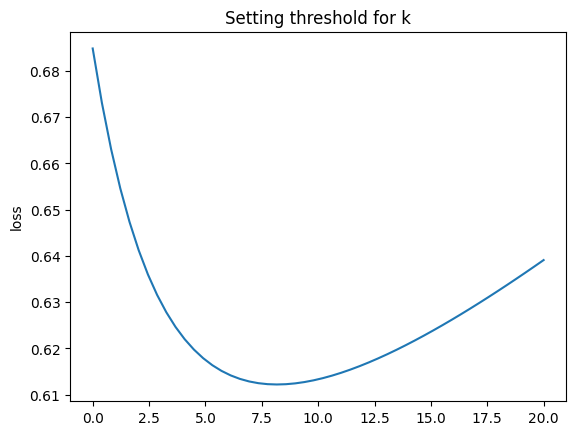

In [ ]:
params = dict(home_points=10, k=8.1, scaling_factor=100, learn_input="score")

k_range = np.linspace(0, 20, 50)
log_loss = []

for k in k_range:

    params["k"] = k

    log_loss += [evaluate_params(train_df, test_df, **params)]


plt.plot(k_range, log_loss)
plt.title("Setting threshold for k")
plt.ylabel("loss")

k_range[np.argmin(log_loss)]

np.float64(12.6)

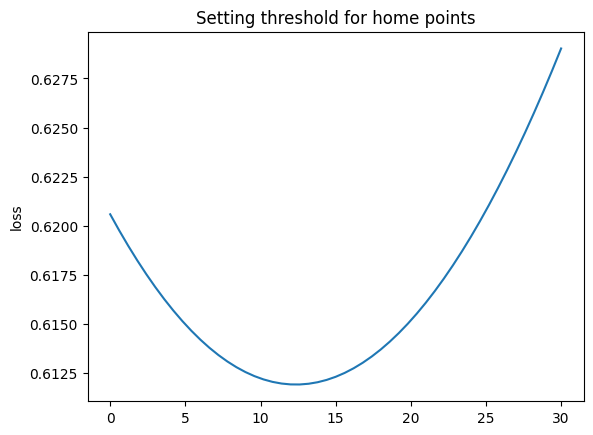

In [ ]:
params = dict(home_points=12, k=8, scaling_factor=100, learn_input="score")

home_points_range = np.linspace(0, 30, 51)
log_loss = []

for home_points in home_points_range:

    params["home_points"] = home_points

    log_loss += [evaluate_params(train_df, test_df, **params)]


plt.plot(home_points_range, log_loss)
plt.title("Setting threshold for home points")
plt.ylabel("loss")

home_points_range[np.argmin(log_loss)]

For a score-based Elo model, we find the best performance with $k=6$ and a home rating of 11.


In [ ]:
params = dict(home_points=12, k=8, scaling_factor=100, learn_input="score")

games_df = get_games(leagues="nwsl", seasons="2025")

ratings_df, _ = elo_learn(games_df, debug=False, **params)

ratings_df.sort_values("rating", ascending=False, ignore_index=True)

,team,rating
0,KC,148.049146
1,SD,113.588604
2,WAS,112.385775
3,POR,105.320700
4,NJY,105.179754
5,SEA,105.102799
6,LOU,103.832766
7,ORL,99.423707
8,NC,93.674776
9,LA,92.920158


# xg

Now for the xG model. One thing to note here is that we have an additional parameter to tune. Typically this is considered to give models an advantage. We'll need to keep that in mind


np.float64(0.7575757575757577)

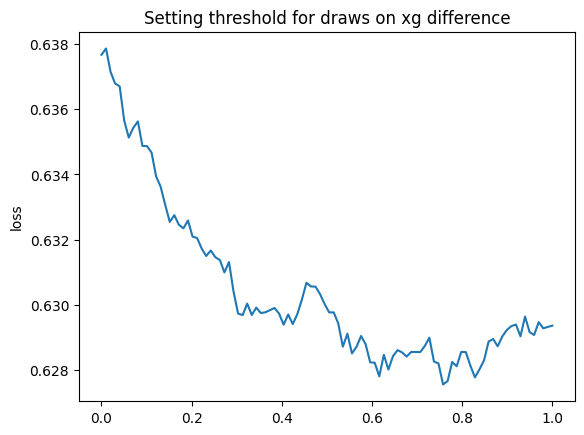

In [ ]:
params = dict(
    home_points=12, k=8, scaling_factor=100, learn_input="xg", goal_diff_draw=0.3
)

goal_diff_draw_range = np.linspace(0, 1, 100)
log_loss = []

for goal_diff_draw in goal_diff_draw_range:

    params["goal_diff_draw"] = goal_diff_draw

    log_loss += [evaluate_params(train_df, test_df, **params)]


plt.plot(goal_diff_draw_range, log_loss)
plt.title("Setting threshold for draws on xg difference")
plt.ylabel("loss")


goal_diff_draw_range[np.argmin(log_loss)]

There's a space of low loss for xg draw thresholds between ~0-0.05. I'll choose 0.03 for now.


np.float64(6.530612244897959)

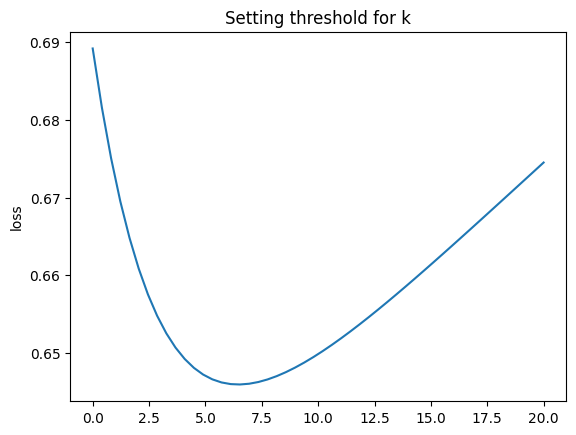

In [ ]:
params = dict(
    home_points=10,
    k=6,
    scaling_factor=100,
    learn_input="xg",
    goal_diff_draw=0.3,
)

k_range = np.linspace(0, 20, 50)
log_loss = []

for k in k_range:

    params["k"] = k

    log_loss += [evaluate_params(train_df, test_df, **params)]


plt.plot(k_range, log_loss)
plt.title("Setting threshold for k")
plt.ylabel("loss")
k_range[np.argmin(log_loss)]

np.float64(9.0)

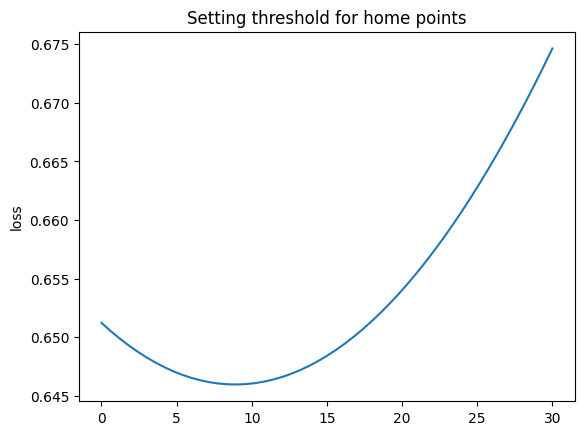

In [ ]:
params = dict(
    home_points=12, k=6, scaling_factor=100, learn_input="xg", goal_diff_draw=0.3
)

home_points_range = np.linspace(0, 30, 51)
log_loss = []

for home_points in home_points_range:

    params["home_points"] = home_points

    log_loss += [evaluate_params(train_df, test_df, **params)]


plt.plot(home_points_range, log_loss)
plt.title("Setting threshold for home points")
plt.ylabel("loss")
home_points_range[np.argmin(log_loss)]

# Comparison


In [ ]:
params = dict(home_points=12, k=6, scaling_factor=100, learn_input="score")

print(
    f"""Score-based Elo model
cross entropy (2019-2024): {evaluate_params(train_df, test_df, **params):.4f}
2025 team ratings:"""
)

games_df = get_games(leagues="nwsl", seasons="2025")

ratings_df, _ = elo_learn(
    games_df,
    # games_df.query("matchday <= 13"),
    **params,
)

ratings_df.sort_values("rating", ascending=False, ignore_index=True)

Score-based Elo model
cross entropy (2019-2024): 0.6608
2025 team ratings:


,team,rating
0,KC,139.794195
1,SD,111.655273
2,WAS,110.149476
3,SEA,104.702524
4,NJY,104.525573
5,POR,104.521855
6,LOU,101.733228
7,ORL,101.286584
8,NC,94.720262
9,LA,94.559749


In [ ]:
params = dict(
    home_points=12, k=6, scaling_factor=100, learn_input="xg", goal_diff_draw=0.3
)

print(
    f"""xG-based Elo model
cross entropy (2019-2024): {evaluate_params(train_df, test_df, **params):.4f}
2025 team ratings:"""
)

games_df = get_games(leagues="nwsl", seasons="2025")

ratings_df, _ = elo_learn(games_df, **params)

ratings_df.sort_values("rating", ascending=False, ignore_index=True)

xG-based Elo model
cross entropy (2019-2024): 0.6466
2025 team ratings:


,team,rating
0,KC,140.902037
1,NC,113.100006
2,POR,112.602051
3,ORL,110.816169
4,LOU,105.512832
5,BAY,104.472714
6,NJY,102.379859
7,WAS,102.156355
8,SD,98.579733
9,LA,92.143935


# Scoreline prediction

In order to project forward season performance from ratings, I'll have to find a way to estimate the scoreline from the ratings.

Let's start at looking at how, across games, the rating difference compares to the goal difference


In [ ]:
def elo_learn(
    games_df,
    k=6,
    home_points=11,
    scaling_factor=100,
    learn_input="score",
    goal_diff_draw=0.30,
):

    games_df = games_df.copy()

    if not "home_rating_pre" in games_df.columns:
        games_df["home_rating_pre"] = 100.0
        games_df["away_rating_pre"] = 100.0
        games_df["home_rating_post"] = 100.0
        games_df["away_rating_post"] = 100.0

    for gid in (
        games_df.sort_values("date_time_utc").query("status=='FullTime'").game_id
    ):

        game_dict = games_df.query(f"game_id == '{gid}'").to_dict(orient="records")[0]

        if learn_input == "score":
            goal_diff = game_dict["home_score"] - game_dict["away_score"]
        elif learn_input == "xg":
            goal_diff = game_dict["home_team_xgoals"] - game_dict["away_team_xgoals"]
        else:
            raise ("learn_input must be either 'score' or 'xg'")

        rating_diff = (
            game_dict["home_rating_pre"] - game_dict["away_rating_pre"] + home_points
        )
        expected_result = 1 / (1 + 10 ** (-rating_diff / scaling_factor))

        if abs(goal_diff) <= 1:
            goal_index = 1
        elif abs(goal_diff) < 3:
            goal_index = (1 + abs(goal_diff)) / 2
        else:
            goal_index = (11 + abs(goal_diff)) / 8

        if abs(goal_diff) < goal_diff_draw:
            result = 0.5
        else:
            result = max(
                goal_diff / abs(goal_diff), 0
            )  # 1 if home wins, 0 if away wins

        points_change = k * goal_index * (result - expected_result)

        game_dict["home_rating_post"] = game_dict["home_rating_pre"] + points_change
        game_dict["away_rating_post"] = game_dict["away_rating_pre"] - points_change

        # set post game rating
        games_df.loc[games_df.game_id == gid, "home_rating_post"] = game_dict[
            "home_rating_post"
        ]
        games_df.loc[games_df.game_id == gid, "away_rating_post"] = game_dict[
            "away_rating_post"
        ]

        # set future pre-game rating

        after_mask = games_df.date_time_utc > game_dict["date_time_utc"]

        # print(
        #     games_df.loc[
        #         after_mask & (games_df.home_team == game_dict["home_team"]),
        #         :,
        #     ]
        # )

        # future home games for today's home team
        games_df.loc[
            after_mask & (games_df.home_team == game_dict["home_team"]),
            "home_rating_pre",
        ] = game_dict["home_rating_post"]
        # future away games for today's home team
        games_df.loc[
            after_mask & (games_df.away_team == game_dict["home_team"]),
            "away_rating_pre",
        ] = game_dict["home_rating_post"]

        # future home games for today's away team
        games_df.loc[
            after_mask & (games_df.home_team == game_dict["away_team"]),
            "home_rating_pre",
        ] = game_dict["away_rating_post"]
        # future away games for today's away team
        games_df.loc[
            after_mask & (games_df.away_team == game_dict["away_team"]),
            "away_rating_pre",
        ] = game_dict["away_rating_post"]

        # update match probabilities

        games_df["ratings_diff"] = (
            games_df["home_rating_pre"] - games_df["away_rating_pre"] + home_points
        )

        home_prob = 1 / (1 + 10 ** (-games_df["ratings_diff"] / scaling_factor))
        games_df["home_prob"] = home_prob

    return games_df

In [ ]:
train_df["goal_differential"] = train_df.home_score - train_df.away_score

elo_out_df = elo_learn(train_df)

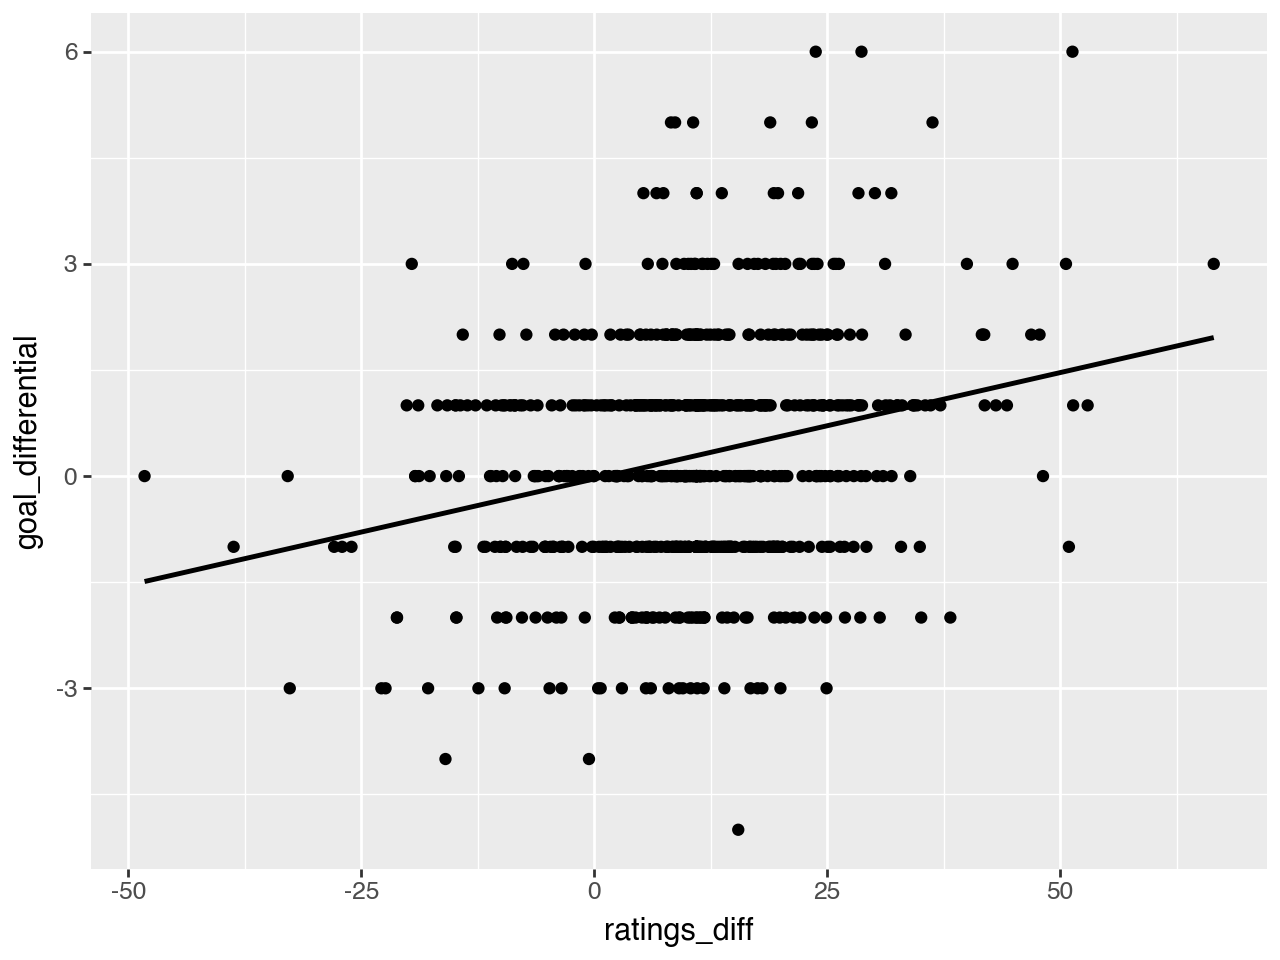

In [ ]:
(
    ggplot(elo_out_df, aes(x="ratings_diff", y="goal_differential"))
    + geom_point()
    + geom_smooth(
        method="lm",
        se=False,
        fullrange=True,
    )
)

In [ ]:
elo_out_df

,game_id,date_time_utc,home_score,away_score,home_team_id,away_team_id,referee_id,stadium_id,home_manager_id,away_manager_id,...,home_xpoints,away_xpoints,matchday_desc,goal_differential,home_rating_pre,away_rating_pre,home_rating_post,away_rating_post,ratings_diff,home_prob
6,eVq3Xl9gQW,2016-04-23 23:30:00 UTC,3,1,XVqKeVKM01,4JMAk47qKg,2vQ1mW4QrA,gpMOzPrQzy,e7Mz3xj5r0,Xj5Yx9RMbd,...,1.741,0.934,nwsl2016md2,2,100.000000,100.000000,103.933137,96.066863,11.000000,0.562985
82,a35re30bML,2016-09-04 22:00:00 UTC,2,1,kRQaWa15KZ,raMyrr25d2,2lqRymD5r0,Pk5L6mmQOW,vzqo3mNqap,wvq9mKNqWn,...,1.727,0.947,nwsl2016md19,1,89.958542,101.957578,92.993045,98.923074,-0.999036,0.494249
156,zeQZBpKNQK,2017-06-29 02:00:00 UTC,3,0,Pk5LeeNqOW,kRQaWa15KZ,p6qb6K4q0G,p6qbX06M0G,9z5krYJMA3,vzqo3mNqap,...,1.557,1.113,nwsl2017md11,3,97.438648,96.270988,101.957973,91.751663,12.167660,0.569588
616,kRQa1NJ1QK,2021-10-16 23:30:00 UTC,3,1,eV5DR6YQKn,XVqKeVKM01,odMX90o5YL,BLMvra8Mxe,Xj5Yznyqbd,NPqxODg59d,...,1.409,1.316,nwsl2021md21,2,83.674106,94.932875,88.187513,90.419469,-0.258769,0.498510
1055,jYQJynekqG,2024-05-24 23:00:00 UTC,2,1,XVqKeVKM01,Pk5LeeNqOW,0Oq6AZ756D,vzqoJrj5ap,jYQJJ1VQGR,XVqKEk0M01,...,1.670,1.094,nwsl2024md11,1,109.156634,113.046945,111.911621,110.291958,7.109689,0.540836
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
268,KXMeGAG3q6,2018-05-26 23:00:00 UTC,0,1,raMyrr25d2,7vQ7BBzqD1,a35rXdGQL6,gpMOoayMzy,NWMWR7eQlz,vzqo3mNqap,...,0.908,1.679,nwsl2018md10,-1,90.717800,110.046579,88.004587,112.759792,-8.328780,0.452202
417,0Oq61WaA56,2019-08-25 00:30:00 UTC,1,2,4JMAk47qKg,raMyrr25d2,Xj5YWgaQbd,0x5g6ojM7O,0Oq6BpAq6D,9YqdZk9MvJ,...,1.402,1.303,nwsl2019md19,-1,92.966475,86.507860,89.371467,90.102868,17.458615,0.599168
594,0Oq6B9nrq6,2021-09-05 20:00:00 UTC,1,1,XVqKeVKM01,4JMAk47qKg,0Oq6AZ756D,vzqoJrj5ap,NPqxODg59d,0Oq6BpAq6D,...,0.875,1.751,nwsl2021md16,0,93.699756,98.996910,93.503069,99.193597,5.702846,0.532781
782,0x5ggvlw57,2022-09-16 23:30:00 UTC,2,0,eV5DR6YQKn,XVqKeVKM01,BLMvnDjMxe,BLMvra8Mxe,2lqReDJ5r0,jYQJJ1VQGR,...,2.076,0.660,nwsl2022md18,2,95.305433,82.718463,98.612612,79.411283,23.586970,0.632536


# Takeaways

The two approachs---raw score vs xG---for estimating team strength perform similarly well, with the xG model perfoming slightly better (0.654 vs 0.668). Because the xG model has an additional free parameter, I'm not ready to say based on this alone that using xG to estimate team strength is strictly superior to using the outcome of games.

However, the fact that using xG is a functional way to estimate team strength at all seems notable to me! xG may not win you games itself, but it does appear to measure something with a strong relationship to team strength---potentially even stronger than the actual outcome of games played!

It's also notable to me that the winning parameters for both the xG and score based models were so similar across 5 seasons of data. Some conclusions form the model:

- there appears to be a home feild advantage worth 10 Elo points. Equivalent to a ~ 10% greater chance of winning (assuming no draws)
- the most predictive "weight index" for NWSL regular season games is 2.5.
- for the best performing xG model, any xG difference below 0.03 is treated as a draw.


In [ ]:
 1 / (1 + 10 ** ((-2)/100))

0.5115108912177917

In [ ]:
0.49 * 0.75

0.3675

In [ ]:
ratings_df

,team,rating
0,ORL,154.489965
1,WAS,148.123233
2,CHI,124.334622
3,HOU,127.386262
4,KC,200.864648
5,POR,163.865671
6,UTA,118.176728
7,BAY,162.310423
8,LOU,157.967845
9,NC,163.724206


In [ ]:
prematch_df = get_predictions(
    ratings_df=ratings_df,
    games_df=decorate_team_ids(
        asa_client.get_games(leagues="nwsl", seasons="2025", status="PreMatch")
    ),
    **params
)

prematch_df

,game_id,date_time_utc,home_team_id,away_team_id,stadium_id,season_name,matchday,knockout_game,status,home_team,home_team_logo,away_team,away_team_logo,home_prob
0,0x5gjnorM7,2025-11-02 20:00:00 UTC,Pk5LeeNqOW,4JMAk47qKg,p6qbX06M0G,2025,26,False,PreMatch,POR,https://american-soccer-analysis-headshots.s3....,HOU,https://american-soccer-analysis-headshots.s3....,0.753298
1,7VqGbYNe5v,2025-11-02 20:00:00 UTC,eV5D2w9QKn,aDQ0lzvQEv,e7MzlRjqr0,2025,26,False,PreMatch,UTA,https://american-soccer-analysis-headshots.s3....,WAS,https://american-soccer-analysis-headshots.s3....,0.398137
2,eVq3bDp65W,2025-11-02 20:00:00 UTC,eV5DR6YQKn,315VnJ759x,BLMvra8Mxe,2025,26,False,PreMatch,LOU,https://american-soccer-analysis-headshots.s3....,BAY,https://american-soccer-analysis-headshots.s3....,0.543966
3,jYQJmL8yqG,2025-11-02 20:00:00 UTC,4wM4rZdqjB,7VqG1lYMvW,xW5p3L0Mg1,2025,26,False,PreMatch,KC,https://american-soccer-analysis-headshots.s3....,SD,https://american-soccer-analysis-headshots.s3....,0.786033
4,KAqBbOVJqb,2025-11-02 20:00:00 UTC,zeQZeazqKw,raMyrr25d2,gpMOrLOQzy,2025,26,False,PreMatch,NC,https://american-soccer-analysis-headshots.s3....,NJY,https://american-soccer-analysis-headshots.s3....,0.603164
5,NWMWp4875l,2025-11-02 20:00:00 UTC,XVqKeVKM01,7vQ7BBzqD1,vzqoJrj5ap,2025,26,False,PreMatch,ORL,https://american-soccer-analysis-headshots.s3....,SEA,https://american-soccer-analysis-headshots.s3....,0.666021
6,Oa5wj2OjM1,2025-11-02 20:00:00 UTC,KPqjw8PQ6v,kRQa8JOqKZ,9YqdkYR5vJ,2025,26,False,PreMatch,CHI,https://american-soccer-analysis-headshots.s3....,LA,https://american-soccer-analysis-headshots.s3....,0.545855
7,Xj5Ypdw0Mb,2025-10-19 21:00:00 UTC,kRQa8JOqKZ,Pk5LeeNqOW,7vQ7xbOMD1,2025,25,False,PreMatch,LA,https://american-soccer-analysis-headshots.s3....,POR,https://american-soccer-analysis-headshots.s3....,0.367826
8,N6MmbPlR5E,2025-10-19 19:00:00 UTC,raMyrr25d2,eV5DR6YQKn,NWMW84L5lz,2025,25,False,PreMatch,NJY,https://american-soccer-analysis-headshots.s3....,LOU,https://american-soccer-analysis-headshots.s3....,0.566233
9,e7Mzj2mXMr,2025-10-19 02:00:00 UTC,7VqG1lYMvW,KPqjw8PQ6v,Oa5wKXY514,2025,25,False,PreMatch,SD,https://american-soccer-analysis-headshots.s3....,CHI,https://american-soccer-analysis-headshots.s3....,0.733726


In [ ]:
prematch_df.query("(home_team == 'LOU') | (away_team == 'LOU')").sort_values(
    "date_time_utc"
)

,game_id,date_time_utc,home_team_id,away_team_id,stadium_id,season_name,matchday,knockout_game,status,home_team,home_team_logo,away_team,away_team_logo,home_prob
55,0Oq6bZwAq6,2025-09-06 00:00:00 UTC,eV5DR6YQKn,Pk5LeeNqOW,BLMvra8Mxe,2025,19,False,PreMatch,LOU,https://american-soccer-analysis-headshots.s3....,POR,https://american-soccer-analysis-headshots.s3....,0.535069
42,gpMOpdan5z,2025-09-15 00:00:00 UTC,7vQ7BBzqD1,eV5DR6YQKn,9Yqda07QvJ,2025,20,False,PreMatch,SEA,https://american-soccer-analysis-headshots.s3....,LOU,https://american-soccer-analysis-headshots.s3....,0.445788
38,wvq9b8gZQW,2025-09-20 02:00:00 UTC,eV5D2w9QKn,eV5DR6YQKn,e7MzlRjqr0,2025,21,False,PreMatch,UTA,https://american-soccer-analysis-headshots.s3....,LOU,https://american-soccer-analysis-headshots.s3....,0.345266
31,7vQ7bjYYqD,2025-09-27 23:30:00 UTC,eV5DR6YQKn,kRQa8JOqKZ,BLMvra8Mxe,2025,22,False,PreMatch,LOU,https://american-soccer-analysis-headshots.s3....,LA,https://american-soccer-analysis-headshots.s3....,0.722795
26,Vj58bpy3Q8,2025-10-04 23:30:00 UTC,zeQZeazqKw,eV5DR6YQKn,gpMOrLOQzy,2025,23,False,PreMatch,NC,https://american-soccer-analysis-headshots.s3....,LOU,https://american-soccer-analysis-headshots.s3....,0.600813
20,aDQ0b2jp5E,2025-10-10 23:30:00 UTC,eV5DR6YQKn,KPqjw8PQ6v,BLMvra8Mxe,2025,24,False,PreMatch,LOU,https://american-soccer-analysis-headshots.s3....,CHI,https://american-soccer-analysis-headshots.s3....,0.740918
8,N6MmbPlR5E,2025-10-19 19:00:00 UTC,raMyrr25d2,eV5DR6YQKn,NWMW84L5lz,2025,25,False,PreMatch,NJY,https://american-soccer-analysis-headshots.s3....,LOU,https://american-soccer-analysis-headshots.s3....,0.566233
2,eVq3bDp65W,2025-11-02 20:00:00 UTC,eV5DR6YQKn,315VnJ759x,BLMvra8Mxe,2025,26,False,PreMatch,LOU,https://american-soccer-analysis-headshots.s3....,BAY,https://american-soccer-analysis-headshots.s3....,0.543966
